# 냥기사의 여행 LoRA 학습 (animagine_xl4)

냥기사의 여행 그림체 LoRA를 학습하고, 학습 1회 시간을 재서 데이터 장수별 실험 일정을 정한다.

- 베이스 모델은 05 IP-Adapter 생성 비교로 정한 animagine_xl4다(10/21 결정).
- 비교 조건은 학습 체크포인트 2개 × 캡션 2개 = 4회다.
  - 체크포인트: Animagine XL 4.0(05에서 비교한 모델) / Animagine XL 4.0 Zero(모델 카드: "This is the base (Zero) model meant for fine-tuning/LoRA training")
  - 캡션: NAI 프롬프트 그대로 / 그림체 태그를 트리거 단어 하나로 교체
- 학습 도구는 설치된 diffusers와 같은 커밋(efe46a5b)의 `examples/text_to_image/train_text_to_image_lora_sdxl.py`다. 노트북에서 별도 프로세스로 실행한다.
- 학습 데이터는 `data/raw/nai/lora_gen` 800장과 `prompts.csv` 캡션이다. 평가용 문구(04 `EVAL_PHRASES`)는 학습 데이터에 들어가지 않았다.

| 설정 | 값 | 근거 |
|---|---|---|
| rank (alpha) | 4 (alpha = rank) | diffusers README SDXL LoRA 예시(rank 미지정 → 스크립트 기본 4), 스크립트가 `lora_alpha=args.rank`로 고정 |
| 학습률 / 스케줄러 / 워밍업 | 1e-4 / constant / 0 | diffusers README 예시 |
| 배치 / 해상도 | 1 / 1024 | diffusers README 예시, 데이터가 모두 1024×1024(03 EDA 6번) |
| 총 스텝 | 1,600 (800장 × 2에폭) | diffusers README 예시 2에폭. 충분한지는 400스텝마다 저장한 중간 결과의 평가로 확인 |
| 정밀도 / VAE | fp16 / `madebyollin/sdxl-vae-fp16-fix` | diffusers README 예시와 SDXL VAE 수치 불안정 안내 |
| 텍스트 인코더 | 학습 안 함 | diffusers README 예시, kohya `train_SDXL-en.md`의 UNet만 학습 권장 |
| 좌우 반전 | 안 함 | 주인공 이미지 24장 확인 결과 칼·방패 문양이 대부분 화면 기준 오른쪽 |
| 장수별 실험 기준 | 총 스텝 고정 | 실험 목적(필요 장수 확인)상 장수 외 조건을 같게 둠 |

## 의존성 설치

In [1]:
# torch·torchvision은 CUDA 빌드를 따로 설치해서 여기서 올리지 않음 (PyPI 기본은 Windows CPU 빌드, 00 노트북)
# 나머지는 학습 스크립트의 requirements_sdxl.txt (datasets, ftfy, tensorboard, Jinja2, peft>=0.17.0)
%pip install datasets ftfy tensorboard Jinja2 "peft>=0.17.0"

   ---------------------------------------- 0.0/846.4 kB ? eta -:--:--
   ---------------------------------------- 846.4/846.4 kB 36.5 MB/s  0:00:00
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ---------------------------------------- 5.5/5.5 MB 28.1 MB/s  0:00:00

   ---------------------------------------- 0/5 [werkzeug]
   ---------------- ----------------------- 2/5 [markdown]
   ------------------------ --------------- 3/5 [tensorboard]
   ------------------------ --------------- 3/5 [tensorboard]
   ------------------------ --------------- 3/5 [tensorboard]
   ------------------------ --------------- 3/5 [tensorboard]
   ------------------------ --------------- 3/5 [tensorboard]
   ------------------------ --------------- 3/5 [tensorboard]
   ------------------------ --------------- 3/5 [tensorboard]
  Attempting uninstall: huggingface-hub
   ------------------------ --------------- 3/5 [tensorboard]
    Found existing installation: huggingface_hub 2.2.

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
faster-whisper 1.2.1 requires onnxruntime<2,>=1.14, which is not installed.
optimum-onnx 0.1.0 requires transformers<4.58.0,>=4.36, but you have transformers 5.20.1 which is incompatible.


## 설정

In [2]:
import json
import os
import shutil
import subprocess
import sys
import threading
import time
import urllib.request
from pathlib import Path

import pandas as pd

ROOT = Path('..')
NAI_DIR = ROOT / 'data' / 'raw' / 'nai'
GEN_DIR = NAI_DIR / 'lora_gen'
DATA_DIR = ROOT / 'data' / 'processed' / 'nai_lora'
LORA_DIR = ROOT / 'models' / 'lora'
OUT_DIR = ROOT / 'outputs' / 'lora_train'
SCRIPT = ROOT / 'src' / 'train' / 'train_text_to_image_lora_sdxl.py'
for d in [DATA_DIR, LORA_DIR, OUT_DIR, SCRIPT.parent]:
    d.mkdir(parents=True, exist_ok=True)
RUNS_CSV = OUT_DIR / 'train_runs.csv'

# 설치된 diffusers(0.41.0.dev0)와 같은 커밋의 학습 스크립트
DIFFUSERS_COMMIT = 'efe46a5b177af67c64b3666da8ddddac7ee12163'
SCRIPT_URL = (f'https://raw.githubusercontent.com/huggingface/diffusers/{DIFFUSERS_COMMIT}'
              '/examples/text_to_image/train_text_to_image_lora_sdxl.py')

CKPTS = {
    'v40': 'cagliostrolab/animagine-xl-4.0',
    'zero': 'cagliostrolab/animagine-xl-4.0-zero',
}
VAE = 'madebyollin/sdxl-vae-fp16-fix'

# 04 노트북 STYLE과 같은 문자열. prompts.csv의 모든 프롬프트가 이 문자열로 끝나는지 데이터 준비에서 확인
STYLE = 'flat color, cel shading, clean thin lineart, soft bright colors, storybook fantasy, anime style, very aesthetic, masterpiece, no text'
# 기존 단어와 겹치지 않게 만든 트리거 단어
TRIGGER = 'nyang_knight_style'
CAPTIONS = ['nai', 'trigger']

TRAIN = dict(resolution=1024, train_batch_size=1, max_train_steps=1600, checkpointing_steps=400,
             learning_rate=1e-4, lr_scheduler='constant', lr_warmup_steps=0, rank=4,
             mixed_precision='fp16', seed=42)
# 첫 학습(v40·nai)의 시간으로 장수별 실험 일정을 계산
RUNS = [(c, cap) for c in CKPTS for cap in CAPTIONS]
print(RUNS)

[('v40', 'nai'), ('v40', 'trigger'), ('zero', 'nai'), ('zero', 'trigger')]


## 환경 확인

In [3]:
import accelerate
import datasets
import diffusers
import peft
import torch
import transformers
from huggingface_hub import list_repo_files

print('torch', torch.__version__, '| cuda', torch.cuda.is_available())
print('diffusers', diffusers.__version__, '| transformers', transformers.__version__, '| peft', peft.__version__,
      '| accelerate', accelerate.__version__, '| datasets', datasets.__version__)
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print('gpu', p.name, f'{p.total_memory / 1024**3:.1f} GB')
print('disk free', round(shutil.disk_usage(ROOT.resolve()).free / 1024**3, 1), 'GB')

# 학습 스크립트는 diffusers 형식(model_index.json, unet/, vae/ ...)의 저장소만 읽음
for name, repo in {**CKPTS, 'vae': VAE}.items():
    files = list_repo_files(repo)
    need = 'model_index.json' if name in CKPTS else 'config.json'
    print(f'{name:5s} {repo:40s} {need}:', need in files, '| unet/:', any(f.startswith('unet/') for f in files))

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Multiple distributions found for package optimum. Picked distribution: optimum
W1021 16:42:21.472000 45204 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1021 16:42:21.596000 45204 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


torch 2.14.1+cu130 | cuda True
diffusers 0.41.0.dev0 | transformers 5.20.1 | peft 0.21.2 | accelerate 1.15.0 | datasets 5.0.1
gpu NVIDIA GeForce RTX 3090 24.0 GB
disk free 108.6 GB
v40   cagliostrolab/animagine-xl-4.0           model_index.json: True | unet/: True
zero  cagliostrolab/animagine-xl-4.0-zero      model_index.json: True | unet/: True
vae   madebyollin/sdxl-vae-fp16-fix            config.json: True | unet/: False


## 학습 스크립트 확보

GitHub의 diffusers 저장소에서 설치된 버전과 같은 커밋의 스크립트를 받는다. 스크립트 안의 `check_min_version`이 설치된 버전(0.41.0.dev0)과 같은지 확인한다.

In [4]:
if not SCRIPT.exists():
    urllib.request.urlretrieve(SCRIPT_URL, SCRIPT)
src = SCRIPT.read_text(encoding='utf-8')
print(SCRIPT, len(src.splitlines()), 'lines')
print('check_min_version("0.41.0.dev0") 포함:', 'check_min_version("0.41.0.dev0")' in src)
print('설치된 diffusers:', diffusers.__version__)

..\src\train\train_text_to_image_lora_sdxl.py 1342 lines
check_min_version("0.41.0.dev0") 포함: True
설치된 diffusers: 0.41.0.dev0


## 데이터 준비

캡션 종류마다 이미지 폴더와 `metadata.jsonl`(`file_name`, `text`)을 만든다. 학습 스크립트가 `imagefolder` 형식으로 읽는다.

- `nai`: `prompts.csv`의 프롬프트 그대로
- `trigger`: 프롬프트 끝의 그림체 태그(`STYLE`)를 트리거 단어로 교체

이미지는 원본과 같은 파일이라 하드링크로 만들고, 하드링크가 안 되면 복사한다.

학습 이미지 800 장 | STYLE로 끝나는 프롬프트 800 개
nai ..\data\processed\nai_lora\nai 이미지 800 | 캡션 800
trigger ..\data\processed\nai_lora\trigger 이미지 800 | 캡션 800
[nai] no humans, black cat adventurer, yellow eyes, red wide-brim hat, ears through headwear, olive green capelet, brown cross-shaped clasp, brown belt, short sword at hip, olive green cape with shield emblem, standing upright, looking at viewer, green fields with a dirt road, daytime, full body, wide shot, flat color, cel shading, clean thin lineart, soft bright colors, storybook fantasy, anime style, very aesthetic, masterpiece, no text
[trigger] no humans, black cat adventurer, yellow eyes, red wide-brim hat, ears through headwear, olive green capelet, brown cross-shaped clasp, brown belt, short sword at hip, olive green cape with shield emblem, standing upright, looking at viewer, green fields with a dirt road, daytime, full body, wide shot, nyang_knight_style


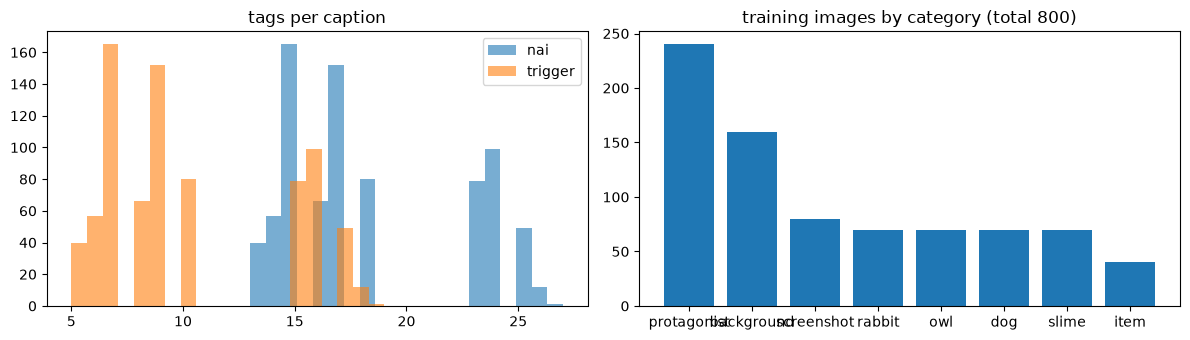

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

prompts = pd.read_csv(GEN_DIR / 'prompts.csv', encoding='utf-8-sig')
prompts = prompts[[(GEN_DIR / f).exists() for f in prompts.file]].reset_index(drop=True)
ends = prompts.prompt.str.endswith(STYLE)
print('학습 이미지', len(prompts), '장 | STYLE로 끝나는 프롬프트', ends.sum(), '개')
assert ends.all(), 'STYLE로 끝나지 않는 프롬프트가 있음 → trigger 캡션을 만들 수 없음'


def caption(prompt, kind):
    if kind == 'nai':
        return prompt
    return prompt[:-len(STYLE)] + TRIGGER


for kind in CAPTIONS:
    d = DATA_DIR / kind
    d.mkdir(parents=True, exist_ok=True)
    with open(d / 'metadata.jsonl', 'w', encoding='utf-8') as f:
        for _, r in prompts.iterrows():
            dst = d / r.file
            if not dst.exists():
                try:
                    os.link(GEN_DIR / r.file, dst)
                except OSError:
                    shutil.copy2(GEN_DIR / r.file, dst)
            f.write(json.dumps({'file_name': r.file, 'text': caption(r.prompt, kind)}, ensure_ascii=False) + '\n')
    n = sum(1 for _ in open(d / 'metadata.jsonl', encoding='utf-8'))
    print(kind, d, '이미지', len(list(d.glob('*.png'))), '| 캡션', n)

ex = prompts.iloc[0]
for kind in CAPTIONS:
    print(f'[{kind}]', caption(ex.prompt, kind))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for kind in CAPTIONS:
    axes[0].hist(prompts.prompt.map(lambda p: len(caption(p, kind).split(','))), bins=20, alpha=0.6, label=kind)
axes[0].set_title('tags per caption')
axes[0].legend()
counts = prompts.category.value_counts()
axes[1].bar(counts.index, counts.values)
axes[1].set_title(f'training images by category (total {len(prompts)})')
plt.tight_layout()
plt.savefig(OUT_DIR / 'train_data.png', dpi=90)
plt.show()

## 학습 실행 함수

- 학습은 별도 프로세스에서 실행하고, 출력은 `outputs/lora_train/logs/{run}.log`에 저장한다.
- 실행 중 `nvidia-smi`로 GPU 메모리 사용량을 2초마다 읽어 최대값을 기록한다.
- 결과(소요 시간, 스텝당 시간, 최대 GPU 메모리, 종료 코드)는 `train_runs.csv`에 추가 저장한다.
- 이미 끝난 학습(`pytorch_lora_weights.safetensors`가 있는 폴더)은 건너뛴다.

In [6]:
LOG_DIR = OUT_DIR / 'logs'
LOG_DIR.mkdir(exist_ok=True)


def gpu_used_mb():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=memory.used', '--format=csv,noheader,nounits'],
                             capture_output=True, text=True, timeout=10).stdout
        return int(out.strip().splitlines()[0])
    except Exception:
        return None


def train(ckpt, cap, steps=TRAIN['max_train_steps'], tag=None):
    run = tag or f'{ckpt}_{cap}'
    out = LORA_DIR / run
    if (out / 'pytorch_lora_weights.safetensors').exists():
        print(run, '이미 학습됨 → 건너뜀')
        return None
    args = {**TRAIN, 'max_train_steps': steps,
            'pretrained_model_name_or_path': CKPTS[ckpt], 'pretrained_vae_model_name_or_path': VAE,
            'train_data_dir': str((DATA_DIR / cap).resolve()), 'image_column': 'image', 'caption_column': 'text',
            'output_dir': str(out.resolve()), 'report_to': 'tensorboard'}
    if steps < TRAIN['checkpointing_steps']:
        args['checkpointing_steps'] = steps
    cmd = [sys.executable, str(SCRIPT.resolve())] + [f'--{k}={v}' for k, v in args.items()]
    peak, stop = [0], threading.Event()

    def watch():
        while not stop.wait(2):
            v = gpu_used_mb()
            if v:
                peak[0] = max(peak[0], v)

    threading.Thread(target=watch, daemon=True).start()
    base_mb = gpu_used_mb()
    t0 = time.perf_counter()
    with open(LOG_DIR / f'{run}.log', 'w', encoding='utf-8') as log:
        p = subprocess.run(cmd, stdout=log, stderr=subprocess.STDOUT,
                           env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    sec = round(time.perf_counter() - t0, 1)
    stop.set()
    rec = dict(run=run, ckpt=ckpt, caption=cap, steps=steps, returncode=p.returncode, sec=sec,
               sec_per_step=round(sec / steps, 3), peak_gpu_mb=peak[0] or None, gpu_mb_before=base_mb,
               finished=time.strftime('%Y-%m-%d %H:%M:%S'))
    pd.DataFrame([rec]).to_csv(RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False, encoding='utf-8')
    print(rec)
    if p.returncode != 0:
        print(''.join(open(LOG_DIR / f'{run}.log', encoding='utf-8', errors='replace').readlines()[-40:]))
    return rec

## 동작 확인 (5스텝)

전체 학습 전에 같은 설정으로 5스텝만 돌려 스크립트가 현재 환경(transformers·peft 버전)에서 끝까지 도는지 확인한다. 결과는 `models/lora/smoke_v40_nai`에 저장되고 평가에는 쓰지 않는다.

In [7]:
smoke = train('v40', 'nai', steps=5, tag='smoke_v40_nai')

{'run': 'smoke_v40_nai', 'ckpt': 'v40', 'caption': 'nai', 'steps': 5, 'returncode': 0, 'sec': 145.1, 'sec_per_step': 29.02, 'peak_gpu_mb': 18381, 'gpu_mb_before': 3384, 'finished': '2026-10-21 16:44:53'}


## 학습 (4회)

체크포인트 × 캡션 4회를 차례로 학습한다. 400스텝마다 `checkpoint-400`·`-800`·`-1200`·`-1600` 폴더에 LoRA 가중치가 저장된다.

In [8]:
for ckpt, cap in RUNS:
    train(ckpt, cap)

{'run': 'v40_nai', 'ckpt': 'v40', 'caption': 'nai', 'steps': 1600, 'returncode': 0, 'sec': 1765.4, 'sec_per_step': 1.103, 'peak_gpu_mb': 18910, 'gpu_mb_before': 3431, 'finished': '2026-10-21 17:14:18'}
{'run': 'v40_trigger', 'ckpt': 'v40', 'caption': 'trigger', 'steps': 1600, 'returncode': 0, 'sec': 1765.4, 'sec_per_step': 1.103, 'peak_gpu_mb': 18607, 'gpu_mb_before': 3637, 'finished': '2026-10-21 17:43:43'}
{'run': 'zero_nai', 'ckpt': 'zero', 'caption': 'nai', 'steps': 1600, 'returncode': 0, 'sec': 1914.1, 'sec_per_step': 1.196, 'peak_gpu_mb': 19098, 'gpu_mb_before': 3511, 'finished': '2026-10-21 18:15:38'}
{'run': 'zero_trigger', 'ckpt': 'zero', 'caption': 'trigger', 'steps': 1600, 'returncode': 0, 'sec': 1706.4, 'sec_per_step': 1.067, 'peak_gpu_mb': 18638, 'gpu_mb_before': 3597, 'finished': '2026-10-21 18:44:04'}


## 학습 시간과 장수별 실험 일정

- 첫 학습(`v40_nai`)의 소요 시간이 10/19 계획의 "LoRA 학습 1회 시간"이다.
- 장수별 실험은 총 스텝을 고정하므로 장수와 관계없이 1회 시간이 같다고 본다. 실험 일정 = 장수 개수 × 1회 시간이다.
- `SWEEP_SIZES`는 장수 후보이고, 실험 전에 정한다.

,run,steps,sec,hours,sec_per_step,peak_gpu_mb,gpu_mb_before
1,v40_nai,1600,1765.4,0.490,1.103,18910,3431
2,v40_trigger,1600,1765.4,0.490,1.103,18607,3637
3,zero_nai,1600,1914.1,0.532,1.196,19098,3511
4,zero_trigger,1600,1706.4,0.474,1.067,18638,3597


,images,hours_each,hours_cumulative
0,50,0.49,0.49
1,100,0.49,0.98
2,200,0.49,1.47
3,400,0.49,1.96
4,800,0.49,2.45


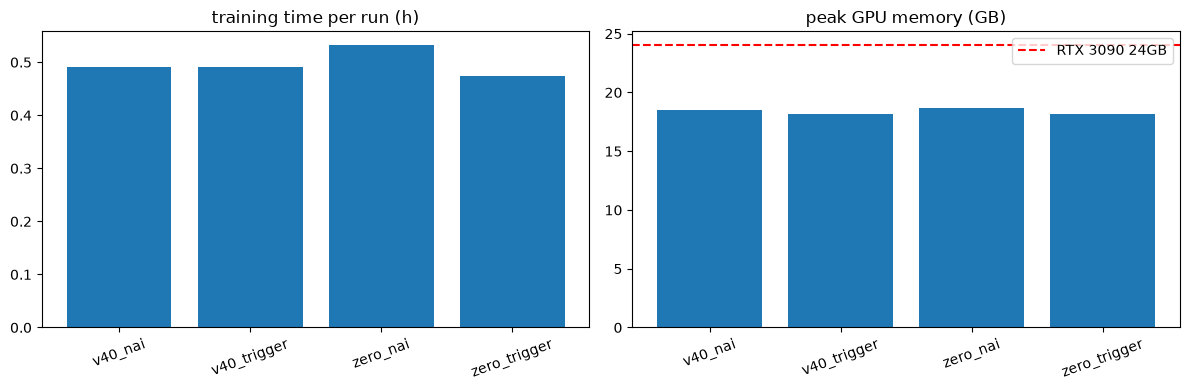

In [9]:
runs = pd.read_csv(RUNS_CSV)
runs = runs[(runs.returncode == 0) & ~runs.run.str.startswith('smoke')].drop_duplicates('run', keep='last')
runs['hours'] = runs.sec / 3600
display(runs[['run', 'steps', 'sec', 'hours', 'sec_per_step', 'peak_gpu_mb', 'gpu_mb_before']].round(3))

SWEEP_SIZES = [50, 100, 200, 400, 800]
one = runs.set_index('run').loc['v40_nai', 'hours']
plan = pd.DataFrame({'images': SWEEP_SIZES, 'hours_each': one})
plan['hours_cumulative'] = plan.hours_each.cumsum()
display(plan.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(runs.run, runs.hours)
axes[0].set_title('training time per run (h)')
axes[0].tick_params(axis='x', rotation=20)
axes[1].bar(runs.run, runs.peak_gpu_mb / 1024)
axes[1].axhline(24, color='red', linestyle='--', label='RTX 3090 24GB')
axes[1].set_title('peak GPU memory (GB)')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'train_time.png', dpi=90)
plt.show()

## 학습 손실

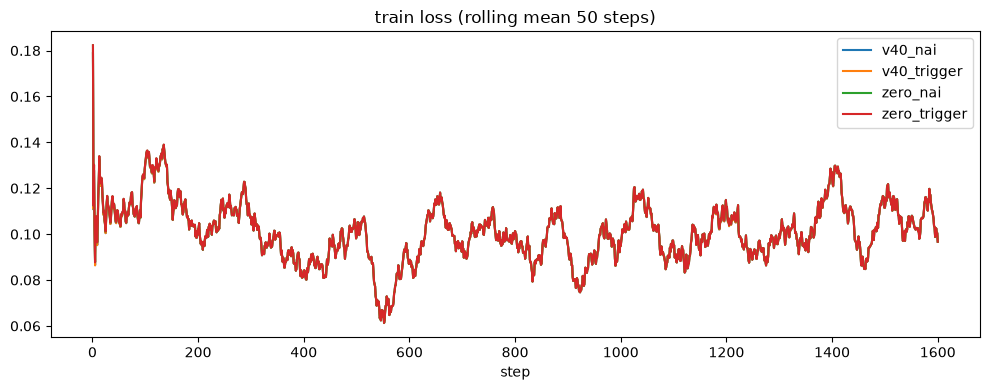

In [10]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

fig, ax = plt.subplots(figsize=(10, 4))
for ckpt, cap in RUNS:
    run = f'{ckpt}_{cap}'
    events = sorted((LORA_DIR / run / 'logs').rglob('events.out.tfevents.*'))
    if not events:
        continue
    acc = EventAccumulator(str(events[-1].parent))
    acc.Reload()
    if 'train_loss' not in acc.Tags().get('scalars', []):
        continue
    s = pd.Series({e.step: e.value for e in acc.Scalars('train_loss')}).sort_index()
    ax.plot(s.index, s.rolling(50, min_periods=1).mean(), label=run)
ax.set_xlabel('step')
ax.set_title('train loss (rolling mean 50 steps)')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'train_loss.png', dpi=90)
plt.show()

## 평가 이미지 생성

- 프롬프트: 주인공 고정 태그(04 `CAT`) + 평가용 문구 4개(04 `EVAL_PHRASES`, 학습 데이터에 없음) + 그림체 부분(`nai` 캡션은 `STYLE`, `trigger` 캡션은 트리거 단어)
- 생성 설정: Animagine XL 4.0 모델 카드 권장값(Euler Ancestral, 28스텝, CFG 5), 1024×1024, seed 0·1
- 조합
  - LoRA 없음: 4.0, Zero (기준선)
  - 4.0에서 학습한 LoRA → 4.0에 적용
  - Zero에서 학습한 LoRA → Zero에 적용, 그리고 4.0에 적용 (Zero에서 학습한 LoRA가 4.0에 맞는지 확인)
  - 각 LoRA는 400·800·1,200·1,600스텝 4개 시점
- 생성마다 `lora_eval.csv`에 바로 저장하고, 다시 실행하면 이미 만든 이미지는 건너뛴다.

In [11]:
import gc

from diffusers import AutoencoderKL, EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

EVAL_DIR = OUT_DIR / 'eval'
EVAL_DIR.mkdir(exist_ok=True)
EVAL_CSV = OUT_DIR / 'lora_eval.csv'
# 04 노트북의 CAT, EVAL_PHRASES와 같은 문자열
CAT = ('no humans, black cat adventurer, yellow eyes, red wide-brim hat, ears through headwear, olive green capelet, '
       'brown cross-shaped clasp, brown belt, short sword at hip, olive green cape with shield emblem')
EVAL_PHRASES = ['sailing a small boat', 'lake at sunset', 'busy market stall', 'snowy mountain village']
EVAL_SEEDS = [0, 1]
STEPS_SAVED = list(range(TRAIN['checkpointing_steps'], TRAIN['max_train_steps'] + 1, TRAIN['checkpointing_steps']))


def eval_prompt(phrase, cap):
    return f'{CAT}, {phrase}, ' + (STYLE if cap in (None, 'nai') else TRIGGER)


# (적용 체크포인트, 학습 체크포인트, 캡션, 스텝). LoRA 없음은 학습 체크포인트·캡션·스텝이 None
COMBOS = [(c, None, None, 0) for c in CKPTS]
for cap in CAPTIONS:
    for step in STEPS_SAVED:
        COMBOS += [('v40', 'v40', cap, step), ('zero', 'zero', cap, step), ('v40', 'zero', cap, step)]


def lora_path(train_ckpt, cap, step):
    run_dir = LORA_DIR / f'{train_ckpt}_{cap}'
    return run_dir / f'checkpoint-{step}'


def combo_name(apply, train_ckpt, cap, step):
    return f'{apply}_base' if train_ckpt is None else f'{apply}__lora-{train_ckpt}-{cap}-s{step}'


done = set(pd.read_csv(EVAL_CSV).file) if EVAL_CSV.exists() else set()
vae = AutoencoderKL.from_pretrained(VAE, torch_dtype=torch.float16)
for apply in CKPTS:
    todo = [c for c in COMBOS if c[0] == apply]
    pipe = StableDiffusionXLPipeline.from_pretrained(CKPTS[apply], vae=vae, torch_dtype=torch.float16).to('cuda')
    pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
    for _, train_ckpt, cap, step in todo:
        name = combo_name(apply, train_ckpt, cap, step)
        files = {(ph, s): f'{name}__p{i}_s{s}.png' for i, ph in enumerate(EVAL_PHRASES) for s in EVAL_SEEDS}
        if all(f in done for f in files.values()):
            continue
        if train_ckpt is not None:
            lp = lora_path(train_ckpt, cap, step)
            if not (lp / 'pytorch_lora_weights.safetensors').exists():
                print('LoRA 없음 → 건너뜀', lp)
                continue
            pipe.load_lora_weights(str(lp), weight_name='pytorch_lora_weights.safetensors', adapter_name='style')
        for (ph, s), f in files.items():
            if f in done:
                continue
            t0 = time.perf_counter()
            img = pipe(prompt=eval_prompt(ph, cap), num_inference_steps=28, guidance_scale=5.0, width=1024, height=1024,
                       generator=torch.Generator('cpu').manual_seed(s)).images[0]
            sec = round(time.perf_counter() - t0, 2)
            img.save(EVAL_DIR / f)
            rec = dict(file=f, combo=name, apply=apply, train_ckpt=train_ckpt or '', caption=cap or '', step=step,
                       phrase=ph, seed=s, sec=sec)
            pd.DataFrame([rec]).to_csv(EVAL_CSV, mode='a', header=not EVAL_CSV.exists(), index=False, encoding='utf-8')
            done.add(f)
        print(name, 'done', flush=True)
        if train_ckpt is not None:
            pipe.unload_lora_weights()
    del pipe
    gc.collect()
    torch.cuda.empty_cache()

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 7/7 [00:02<00:00,  3.35it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (83 > 77). Running this sequence through the model will result in indexing errors
[transformers] Ignoring clean_up_tokenization_spaces=T

v40_base done

INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.3.4
Transformers : 5.20.1
Torch        : 2.14.1+cu130
Triton       : 3.7.1.post27


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModelWithProjection found with the prefix='text_encoder_2'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModelWithProjection related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: [', very aesthetic , masterpiece , no text']
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: [', very aestheti

v40__lora-v40-nai-s400 done


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModelWithProjection found with the prefix='text_encoder_2'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModelWithProjection related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: [', very aesthetic , masterpiece , no text']
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: [', very aestheti

v40__lora-zero-nai-s400 done


... (42 outputs left out)

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModelWithProjection found with the prefix='text_encoder_2'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModelWithProjection related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
100%|██████████| 28/28 [00:10<00:00,  2.79it/s]


zero__lora-zero-trigger-s1200 done


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModelWithProjection found with the prefix='text_encoder_2'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModelWithProjection related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
100%|██████████| 28/28 [00:10<00:00,  2.71it/s]


zero__lora-zero-trigger-s1600 done


## 그림체 점수

- `style_sim`: 생성 이미지와 냥기사 원본 NAI 이미지(`data/raw/nai`의 17장, 학습 데이터 800장과 별개)의 CLIP 평균 코사인 유사도다. 05와 같은 CLIP(`openai/clip-vit-base-patch32`)을 쓴다.
- 기준선: 원본 17장끼리의 평균 유사도와, LoRA 없는 4.0·Zero의 점수

In [12]:
import numpy as np
from transformers import CLIPModel, CLIPProcessor

CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


@torch.no_grad()
def embed(paths, bs=16):
    out = []
    for i in range(0, len(paths), bs):
        x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
        # transformers 5.x: get_image_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
        e = clip.get_image_features(**x).pooler_output
        out.append(torch.nn.functional.normalize(e, dim=-1).float().cpu())
    return torch.cat(out).numpy()


orig = sorted(NAI_DIR.glob('*.png'))
ORIG_EMB = embed(orig)
orig_base = float((ORIG_EMB @ ORIG_EMB.T)[~np.eye(len(orig), dtype=bool)].mean())
print('원본', len(orig), '장 | 원본끼리 평균 유사도(기준선):', round(orig_base, 3))

ev = pd.read_csv(EVAL_CSV, keep_default_na=False).drop_duplicates('file', keep='last')
E = embed([EVAL_DIR / f for f in ev.file])
ev['style_sim'] = (E @ ORIG_EMB.T).mean(1)
ev.to_csv(OUT_DIR / 'lora_eval_scored.csv', index=False, encoding='utf-8-sig')
summary = ev.groupby(['apply', 'train_ckpt', 'caption', 'step'], sort=False).agg(
    style_sim=('style_sim', 'mean'), style_std=('style_sim', 'std'), n=('file', 'size'), sec=('sec', 'mean')).reset_index()
summary.to_csv(OUT_DIR / 'lora_eval_summary.csv', index=False, encoding='utf-8-sig')
display(summary.round(4))

INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/revision/main "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/openai/clip-vit-base-patch32/resolve/main/model.safetensors "HTTP/1.1 404 Not Found"
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 14617.37it/s]
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/commits/main "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/discussions?p=0 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/commits/refs%2Fpr%2F66 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/openai/clip-vit-base-patch32/resolve/refs%2Fpr%2F66/model.safetensors.index.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/revision/main "HTTP/1.1 200 OK"
INF

원본 17 장 | 원본끼리 평균 유사도(기준선): 0.687


,apply,train_ckpt,caption,step,style_sim,style_std,n,sec
0,v40,,,0,0.6699,0.0575,8,9.8788
1,v40,v40,nai,400,0.7344,0.0198,8,10.9250
2,v40,zero,nai,400,0.7435,0.0220,8,10.9075
3,v40,v40,nai,800,0.7383,0.0074,8,10.9862
4,v40,zero,nai,800,0.7557,0.0113,8,10.8838
5,v40,v40,nai,1200,0.7510,0.0110,8,10.8600
6,v40,zero,nai,1200,0.7611,0.0091,8,10.8250
7,v40,v40,nai,1600,0.7485,0.0077,8,10.8150
8,v40,zero,nai,1600,0.7553,0.0112,8,10.7938
9,v40,v40,trigger,400,0.7156,0.0155,8,10.9312


## 시각화

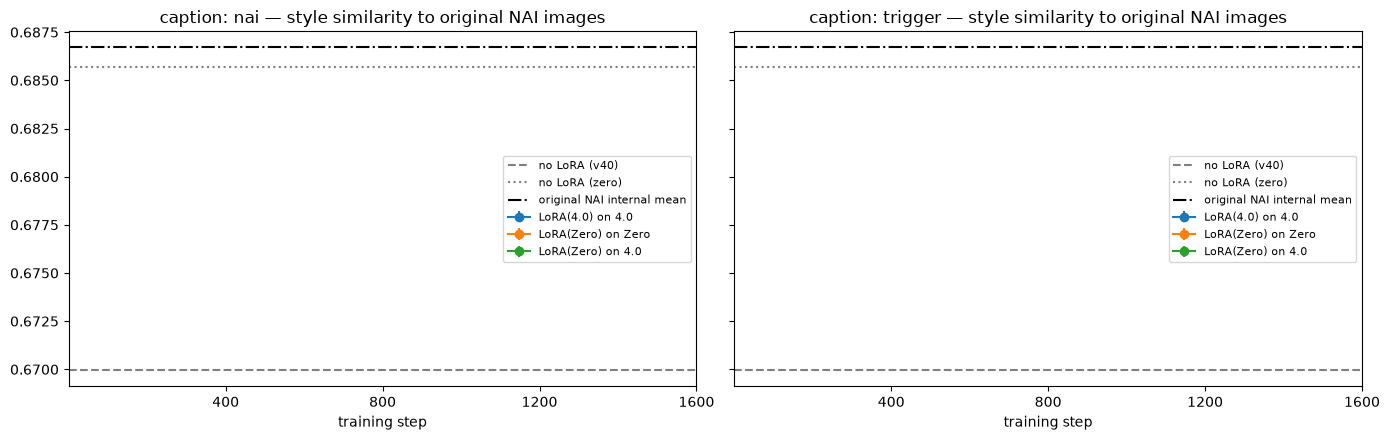

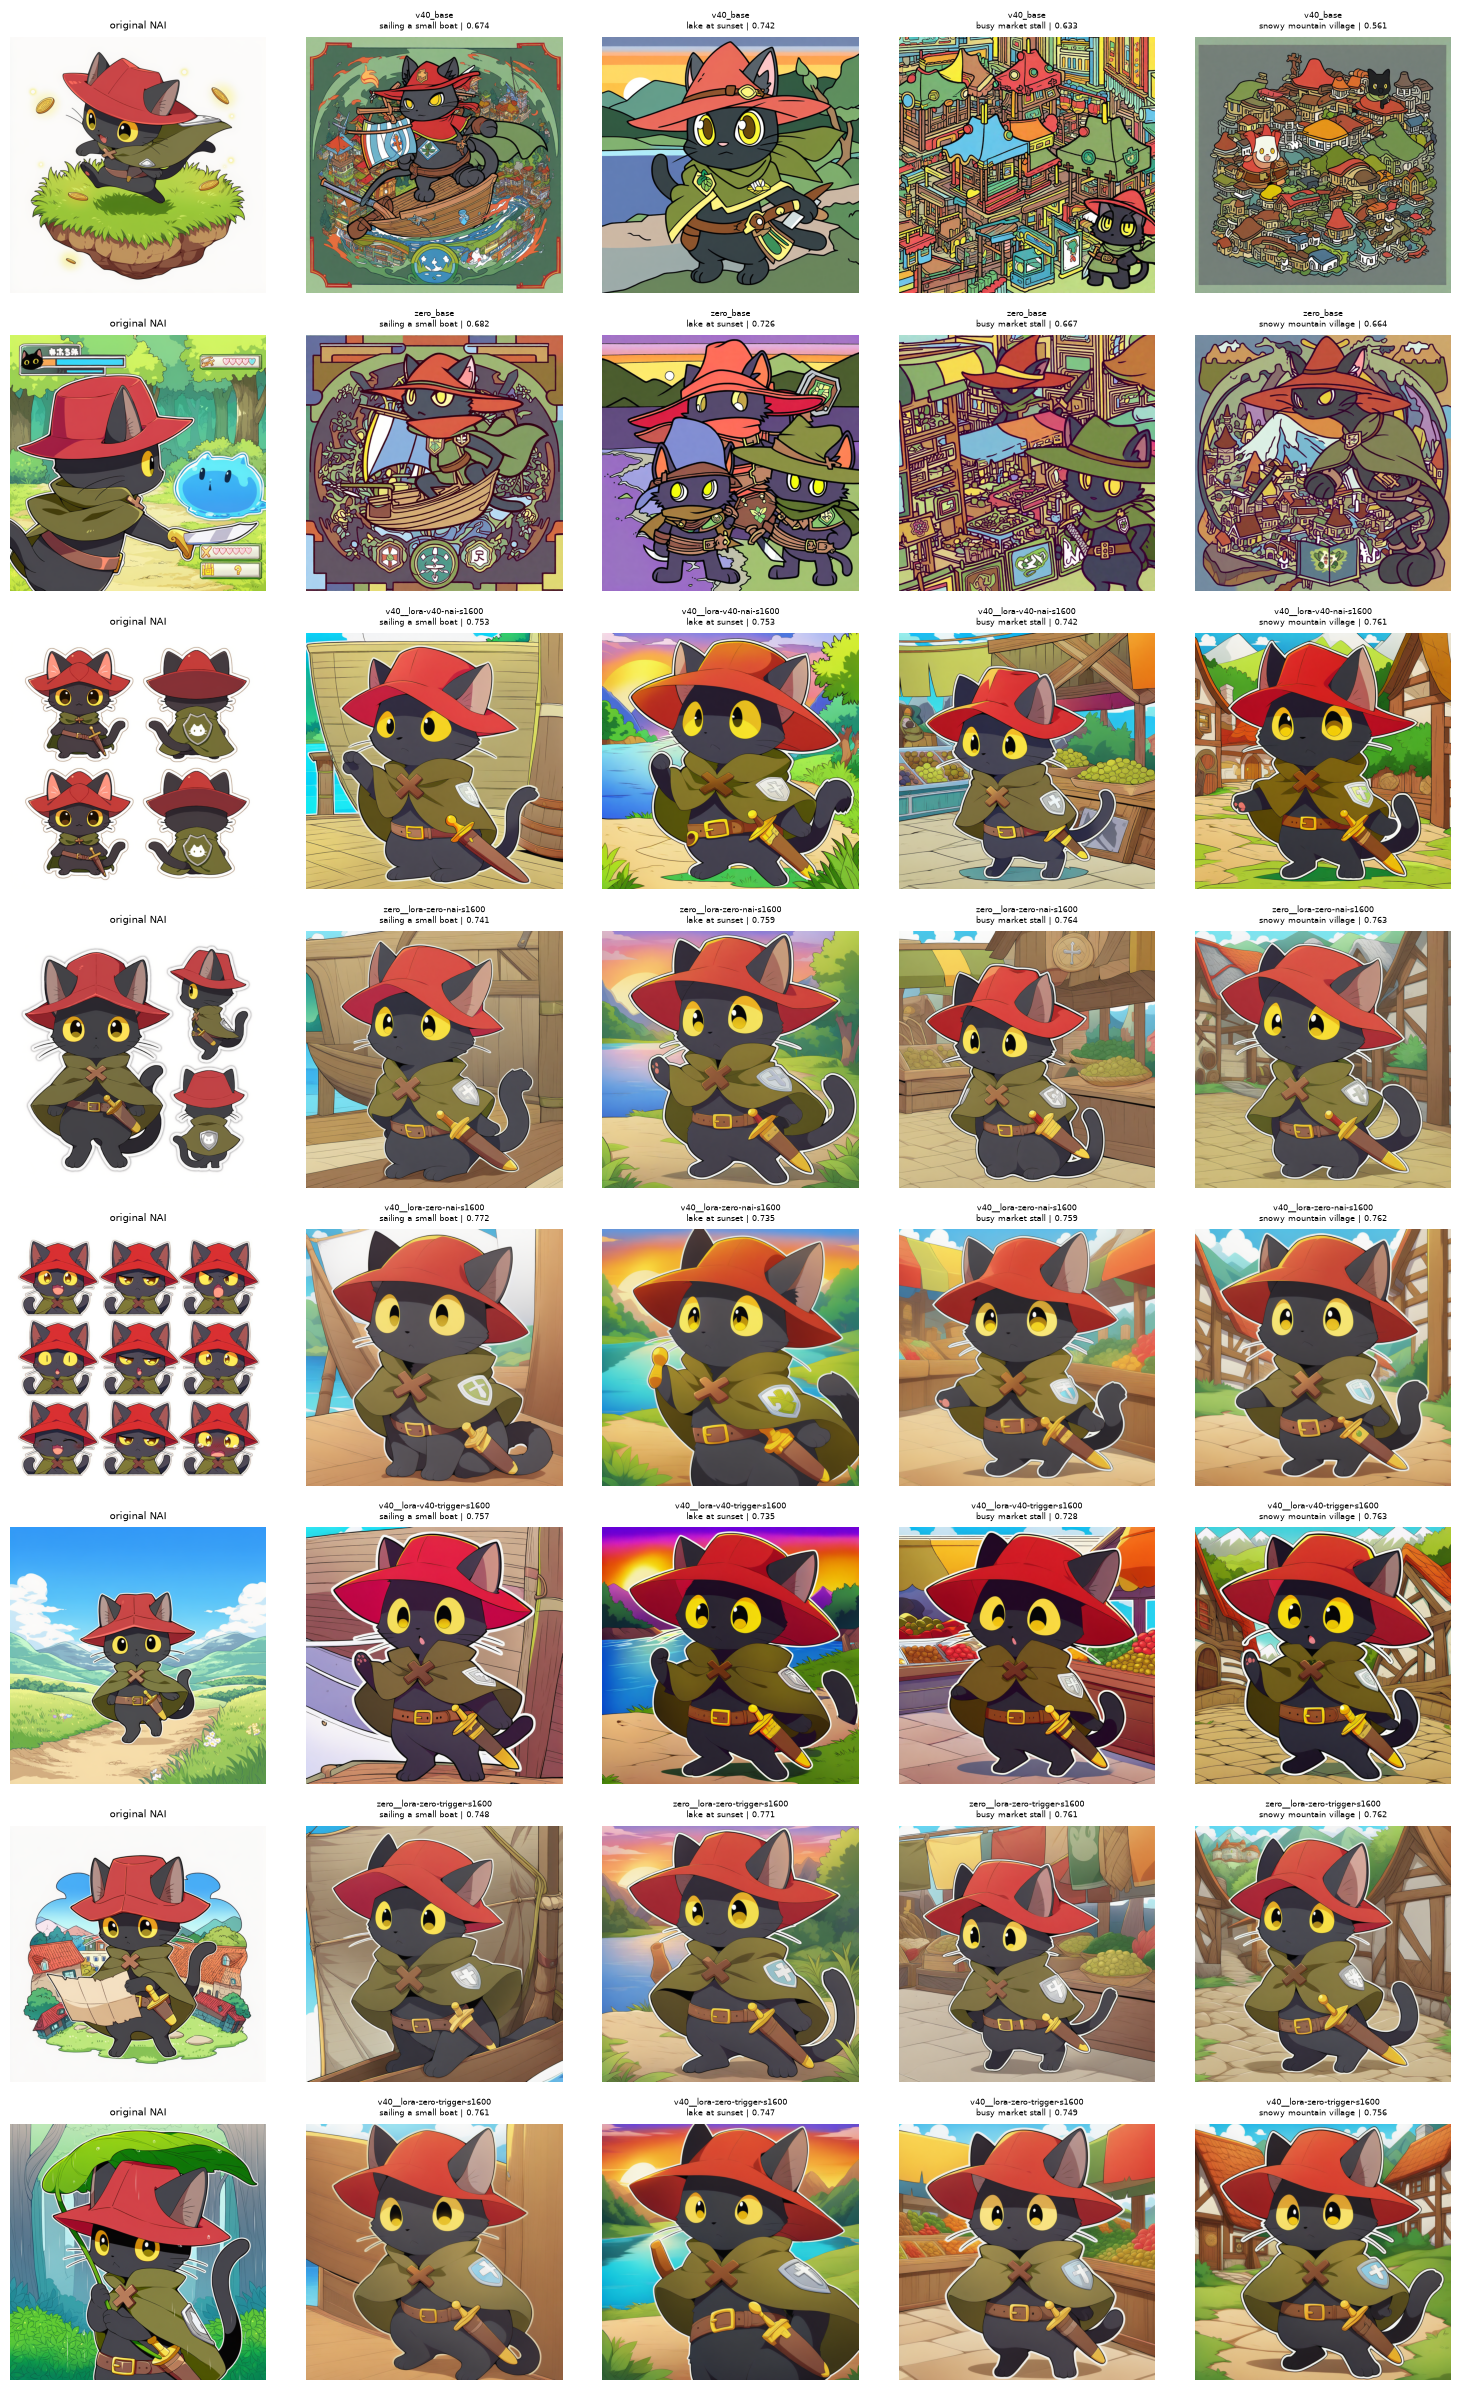

In [14]:
base = summary[summary.train_ckpt == ''].set_index('apply').style_sim
lines_ = [('v40', 'v40', 'LoRA(4.0) on 4.0'), ('zero', 'zero', 'LoRA(Zero) on Zero'), ('v40', 'zero', 'LoRA(Zero) on 4.0')]
fig, axes = plt.subplots(1, len(CAPTIONS), figsize=(7 * len(CAPTIONS), 4.5), sharey=True)
for ax, cap in zip(np.atleast_1d(axes), CAPTIONS):
    for apply, tr, label in lines_:
        s = summary[(summary.apply == apply) & (summary.train_ckpt == tr) & (summary.caption == cap)].sort_values('step')
        ax.errorbar(s.step, s.style_sim, yerr=s.style_std, marker='o', capsize=3, label=label)
    for apply, ls in [('v40', '--'), ('zero', ':')]:
        if apply in base:
            ax.axhline(base[apply], color='gray', linestyle=ls, label=f'no LoRA ({apply})')
    ax.axhline(orig_base, color='black', linestyle='-.', label='original NAI internal mean')
    ax.set_xticks(STEPS_SAVED)
    ax.set_xlabel('training step')
    ax.set_title(f'caption: {cap} — style similarity to original NAI images')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / 'lora_style_sim.png', dpi=90)
plt.show()

# 조합별 그리드 (seed 0): 행 = 조합(마지막 스텝), 열 = 평가 문구
final = [c for c in COMBOS if c[3] in (0, STEPS_SAVED[-1])]
fig, axes = plt.subplots(len(final), len(EVAL_PHRASES) + 1, figsize=(3 * (len(EVAL_PHRASES) + 1), 3 * len(final)), squeeze=False)
for r, c in enumerate(final):
    name = combo_name(*c)
    axes[r, 0].imshow(Image.open(orig[r % len(orig)]).convert('RGB'))
    axes[r, 0].set_title('original NAI', fontsize=7)
    for j, ph in enumerate(EVAL_PHRASES):
        ax = axes[r, j + 1]
        f = EVAL_DIR / f'{name}__p{j}_s0.png'
        if f.exists():
            ax.imshow(Image.open(f))
            sc = ev.loc[ev.file == f.name, 'style_sim']
            ax.set_title(f'{name}\n{ph} | {sc.iloc[0]:.3f}' if len(sc) else name, fontsize=6)
    for ax in axes[r]:
        ax.axis('off')
plt.tight_layout()
plt.savefig(OUT_DIR / 'lora_eval_grid.png', dpi=80)
plt.show()

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1022 09:52:33.399000 29272 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1022 09:52:33.501000 29272 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 19787.03it/s]


,label,step,style_sim,scene_sim,scene_top1,n
0,v40 no LoRA,0,0.6699,0.2093,0.625,8
1,LoRA(v40) on v40 / nai,400,0.7344,0.1935,0.375,8
2,LoRA(zero) on v40 / nai,400,0.7435,0.1856,0.500,8
3,LoRA(v40) on v40 / nai,800,0.7383,0.1848,0.375,8
4,LoRA(zero) on v40 / nai,800,0.7557,0.1847,0.375,8
5,LoRA(v40) on v40 / nai,1200,0.7510,0.1875,0.375,8
6,LoRA(zero) on v40 / nai,1200,0.7611,0.1825,0.250,8
7,LoRA(v40) on v40 / nai,1600,0.7485,0.1921,0.500,8
8,LoRA(zero) on v40 / nai,1600,0.7553,0.1895,0.375,8
9,LoRA(v40) on v40 / trigger,400,0.7156,0.1867,0.500,8


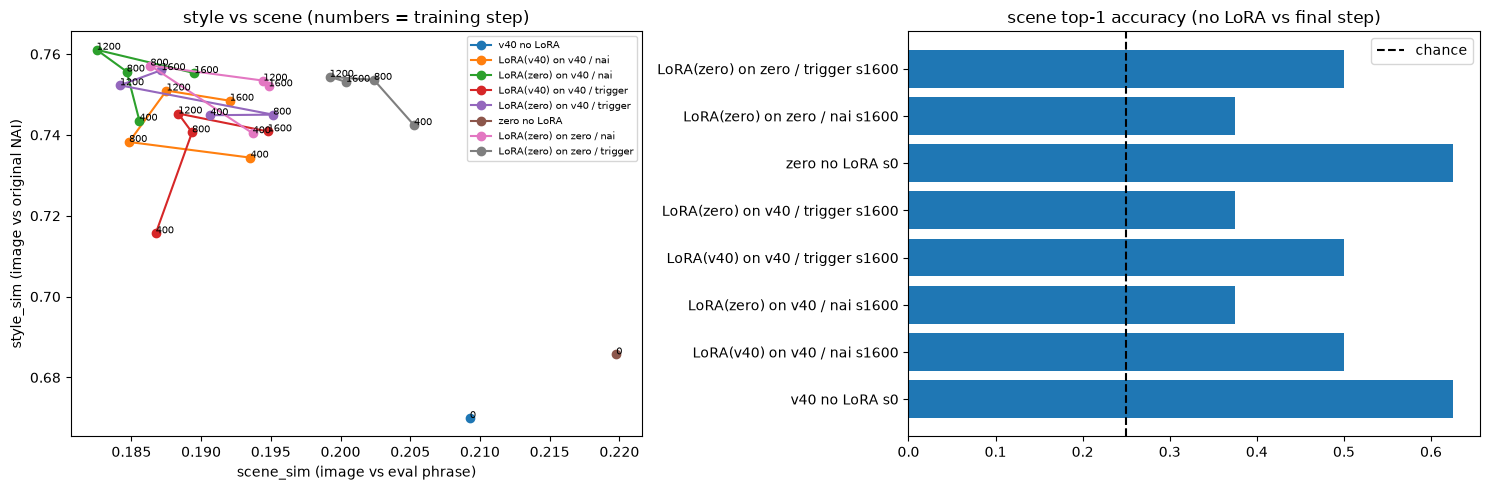

In [1]:
# 장면 반영 점수: 그림체 점수(style_sim)는 프롬프트 장면을 따랐는지는 재지 않아서 따로 잼 (lora_eval_grid.png에서 LoRA 이미지가 거의 같은 정면 구도)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

OUT_DIR = Path('../outputs/lora_train')
EVAL_DIR = OUT_DIR / 'eval'
EVAL_PHRASES = ['sailing a small boat', 'lake at sunset', 'busy market stall', 'snowy mountain village']
CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


ev = pd.read_csv(OUT_DIR / 'lora_eval_scored.csv', keep_default_na=False)
with torch.no_grad():
    t = clip_proc(text=EVAL_PHRASES, return_tensors='pt', padding=True).to('cuda')
    T = torch.nn.functional.normalize(feat(clip.get_text_features(**t)), dim=-1).float().cpu().numpy()
    E = []
    for i in range(0, len(ev), 16):
        x = clip_proc(images=[Image.open(EVAL_DIR / f).convert('RGB') for f in ev.file[i:i + 16]], return_tensors='pt').to('cuda')
        E.append(torch.nn.functional.normalize(feat(clip.get_image_features(**x)), dim=-1).float().cpu())
    E = torch.cat(E).numpy()
S = E @ T.T
idx = ev.phrase.map(EVAL_PHRASES.index).values
ev['scene_sim'] = S[np.arange(len(ev)), idx]
ev['scene_top1'] = S.argmax(1) == idx
ev['label'] = np.where(ev.train_ckpt == '', ev['apply'] + ' no LoRA',
                       'LoRA(' + ev.train_ckpt + ') on ' + ev['apply'] + ' / ' + ev.caption)
summ = ev.groupby(['label', 'step'], sort=False).agg(style_sim=('style_sim', 'mean'), scene_sim=('scene_sim', 'mean'),
                                                     scene_top1=('scene_top1', 'mean'), n=('file', 'size')).reset_index()
summ.to_csv(OUT_DIR / 'lora_eval_scene.csv', index=False, encoding='utf-8-sig')
display(summ.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for lab, s in summ.groupby('label', sort=False):
    s = s.sort_values('step')
    axes[0].plot(s.scene_sim, s.style_sim, marker='o', label=lab)
    for _, r in s.iterrows():
        axes[0].annotate(int(r.step), (r.scene_sim, r.style_sim), fontsize=7)
axes[0].set_xlabel('scene_sim (image vs eval phrase)')
axes[0].set_ylabel('style_sim (image vs original NAI)')
axes[0].set_title('style vs scene (numbers = training step)')
axes[0].legend(fontsize=7)
last = summ[summ.step.isin([0, summ.step.max()])]
axes[1].barh(last.label + ' s' + last.step.astype(str), last.scene_top1)
axes[1].axvline(1 / len(EVAL_PHRASES), color='black', linestyle='--', label='chance')
axes[1].set_title('scene top-1 accuracy (no LoRA vs final step)')
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'lora_eval_scene.png', dpi=90)
plt.show()